In [1]:
from astropy.io import fits, ascii
from astropy.wcs import WCS
from astropy.table import Table, Column, join
from astropy.coordinates import SkyCoord, match_coordinates_sky
from astropy.visualization import simple_norm
from astropy.convolution import Tophat2DKernel, Gaussian2DKernel, Box2DKernel, convolve
from astropy.stats import sigma_clipped_stats
from astropy.nddata import Cutout2D
from astropy.modeling.models import Sersic2D
import astropy.units as u

from photutils.aperture import CircularAperture, CircularAnnulus
from photutils.aperture import aperture_photometry
from photutils.segmentation import detect_threshold, detect_sources
from photutils.segmentation import SegmentationImage

import sep
import math
import statistics
import subprocess
import webbpsf

from numpy import *
from math import *
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.path as mplPath
%matplotlib inline

import time
import statmorph
from statmorph.utils.image_diagnostics import make_figure

**WARNING**: LOCAL JWST PRD VERSION PRDOPSSOC-062 CANNOT BE CHECKED AGAINST ONLINE VERSION


In [2]:
! conda list statmorph

# packages in environment at /Users/gourabnandi/anaconda3:
#
# Name                    Version                   Build  Channel
statmorph                 0.7.0                    pypi_0    pypi


In [3]:
! conda list photutils

# packages in environment at /Users/gourabnandi/anaconda3:
#
# Name                    Version                   Build  Channel
photutils                 2.0.2                    pypi_0    pypi


In [78]:
path = '/Users/gourabnandi/OneDrive - University of Missouri/Astronomy/AstroWorks/JADES_galfit/GOODSS/m0912_z0307_f150w_statmorph/'

image = fits.open(path+'cutout_sci_204131.0.fits')[0].data
segmap = fits.open(path+'sep_segmap_204131.0.fits')[0].data ### generated w/ sep
weightmap = fits.open(path+'cutout_err_204131.0.fits')[0].data
mask = fits.open(path+'mask_204131.0.fits')[0].data

psf = fits.open(path+'psf_f150w.fits')[0].data

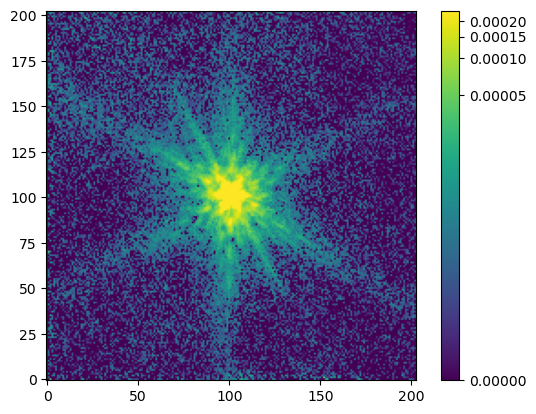

In [79]:
plt.imshow(psf, origin='lower', norm=simple_norm(psf, 'log', percent=99.))
plt.colorbar()
plt.show()

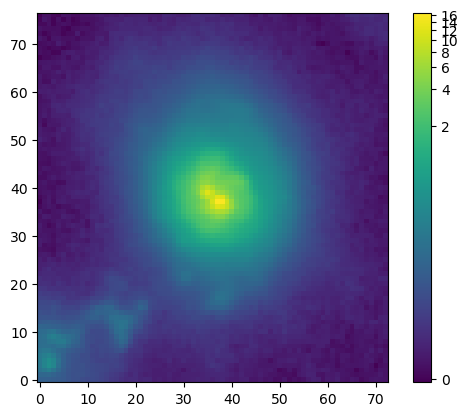

In [80]:
plt.imshow(image, origin='lower', norm=simple_norm(image, 'log', percent=100.))
plt.colorbar()
plt.show()

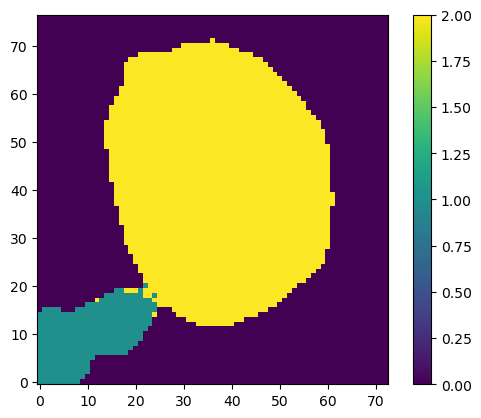

In [81]:
plt.imshow(segmap, origin='lower', cmap='viridis', norm=simple_norm(segmap, 'linear', percent=99.))
plt.colorbar()
plt.show() # 1 o'clock neighbor is blended w/ central source!

In [82]:
np.unique(segmap)

array([0, 1, 2], dtype='>i4')

segmap_jades: (77, 73) >i4


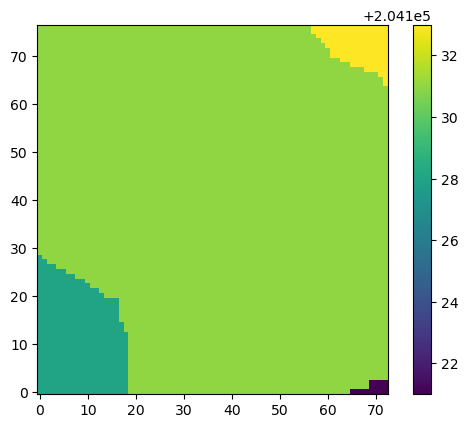

In [88]:
segmap_jades = fits.open(path+'cutout_segmap_204131.0.fits')[0].data ### USE ZSCALEINTERVAL TO BETTER VISUALIZE
print("segmap_jades:",     segmap_jades.shape,     segmap_jades.dtype)

plt.imshow(segmap_jades, origin='lower', cmap='viridis', norm=simple_norm(segmap_jades, 'linear', percent=100.))
plt.colorbar() 
plt.show()

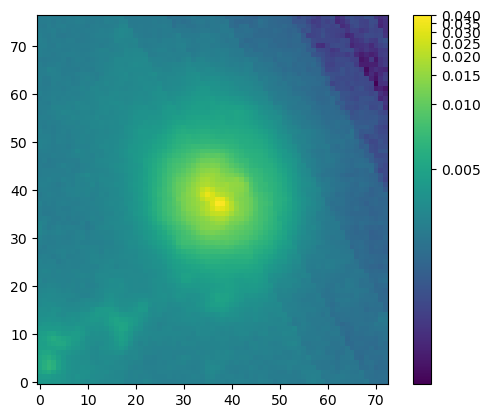

In [89]:
plt.imshow(weightmap, origin='lower', norm=simple_norm(weightmap, 'log', percent=100.))
plt.colorbar()
plt.show()

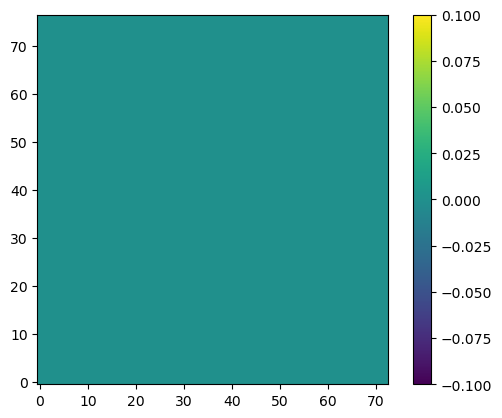

In [92]:
plt.imshow(mask, origin='lower')#, norm=simple_norm(mask, 'linear', percent=100.))
plt.colorbar()
plt.show()

In [93]:
print("image:",      image.shape,      image.dtype)
print("segmap:",     segmap.shape,     segmap.dtype) ## segmap generated by sep
print("mask:",       mask.shape,       mask.dtype) ## mask is not boolean
print("weightmap:",  weightmap.shape,  weightmap.dtype)

image: (77, 73) >f4
segmap: (77, 73) >i4
mask: (77, 73) >f8
weightmap: (77, 73) >f4


In [94]:
# Anything non‑zero becomes True, zeros become False
mask_bool = mask.astype(bool)          # or np.asarray(mask, dtype=bool)

print(mask_bool.shape, mask_bool.dtype)   # → (153, 145) bool

(77, 73) bool


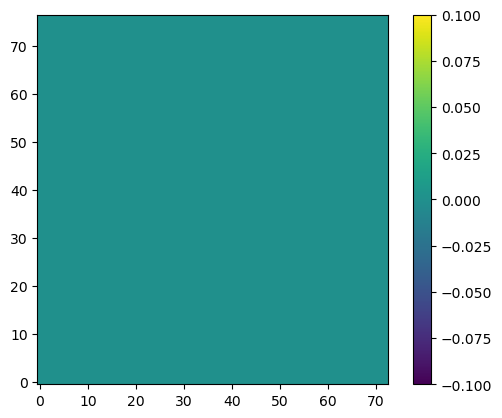

In [96]:
plt.imshow(mask_bool, origin='lower')#, norm=simple_norm(mask, 'log', percent=100.))
plt.colorbar()
plt.show()

In [99]:
# --------------------------------------------
# 1) Build a combined "ignore" mask
# --------------------------------------------
#   segmap_jades > 0  → pixels assigned to *any* object
#   mask_bool   → your existing bad‑pixel map (True = bad pixel)

# ignore = (segmap_jades > 0) | mask_bool          # shape (153, 145), dtype=bool
# ignore = (segmap_jades > 0)
ignore = (segmap > 0)

# --------------------------------------------
# 2) 3‑sigma‑clipped sky statistics
# --------------------------------------------
sky_mean, sky_median, sky_std = sigma_clipped_stats(
    image,
    mask=ignore,
    sigma=3.0,         # 3 σ clipping
    maxiters=5,        # a couple of iterations is plenty
)

print(f"Clipped sky: median={sky_median:.6g},  σ={sky_std:.6g}") 

#### galfit-feedme-file --> sky background at center of fitting region [ADUs] -->7.34e-5

# --------------------------------------------
# 3) Subtract the median from the science image
# --------------------------------------------
image_bsub = image - sky_median

Clipped sky: median=0.0145827,  σ=0.00908285


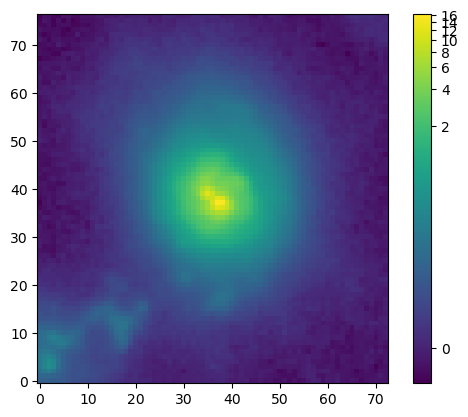

In [100]:
plt.imshow(image_bsub, origin='lower', norm=simple_norm(image_bsub, 'log', percent=99.99))
plt.colorbar()
plt.show()

In [101]:
labels_jades = np.unique(segmap_jades)
labels_jades = labels_jades[labels_jades > 0]             # drop the background (0)

print("labels in this stamp:", labels_jades)   # e.g. [1 4 5]

labels in this stamp: [204121 204128 204131 204133]


In [102]:
#####################################################################################

In [103]:
# ----- read the segmentation map as a NumPy array -----
segmap_data = fits.getdata(path + "sep_segmap_204131.0.fits")   # shape (153,145)
segmap_data = segmap_data.astype(int)                       # ensure integer labels

# look at the labels
labels = np.unique(segmap_data)
labels = labels[labels > 0]             # drop the background (0)
print("labels in this stamp:", labels)   # e.g. [1 4 5]

labels in this stamp: [1 2]


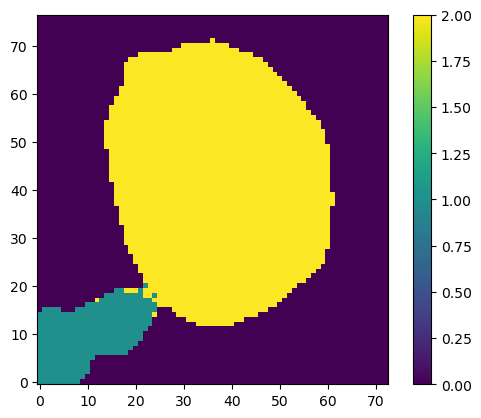

In [104]:
plt.imshow(segmap_data, origin='lower', cmap='viridis')
plt.colorbar()
plt.show()

In [105]:
###################################################################################################################

In [117]:
# let statmorph build a larger stamp  (default cutout_extent=4)
# cutout_extent = 8          # 8 × semi‑major axis from the segmap ellipse

############################################## DID NOT WORK ###########################################################################################
# good_morphs = []
# bad_ids     = []

# for label in labels:
#     try:
#         m = statmorph.source_morphology(
#                 image_bsub, segmap_data, label=label,
#                 weightmap=weightmap, mask=mask_bool, psf=psf,
#                 cutout_extent=cutout_extent, skybox_size=50, 
#                 petro_extent_flux=4, verbose=True) # make room for internal sky estimate -> still useful for objects near the edge
#         good_morphs.append(m)
#     except ValueError as e:
#         print(f"Skipping {label}: {e}")
#         bad_ids.append(label)
#########################################################################################################################################
start = time.time()

morph = statmorph.SourceMorphology( # morphs is a list of SourceMorphology objects (one per label)
#     image,
    image_bsub,
#    segmap_jades,
    segmap_data,            
    weightmap=weightmap,
    mask=mask_bool,
    psf=psf,
    label=2, # label=204131 for segmap_jades
    cutout_extent=10,
    skybox_size=60,
    petro_extent_flux=4,
    verbose=True
)

print('Time: %g s.' % (time.time() - start))

Time: 0.360626 s.


In [118]:
print('SERSIC MODEL')
print('sersic_amplitude =', morph.sersic_amplitude)
print('sersic_rhalf =', morph.sersic_rhalf)
print('sersic_n =', morph.sersic_n)
print('sersic_xc =', morph.sersic_xc)
print('sersic_yc =', morph.sersic_yc)
print('sersic_ellip =', morph.sersic_ellip)
print('sersic_theta =', morph.sersic_theta)
print('sersic_chi2_dof =', morph.sersic_chi2_dof)


SERSIC MODEL
sersic_amplitude = 3.0973724428946943
sersic_rhalf = 5.864732250396129
sersic_n = 1.188730382916742
sersic_xc = 36.64167200786781
sersic_yc = 37.84824693632677
sersic_ellip = 0.1283577342667737
sersic_theta = 2.083004665095358
sersic_chi2_dof = 113.97846466835973


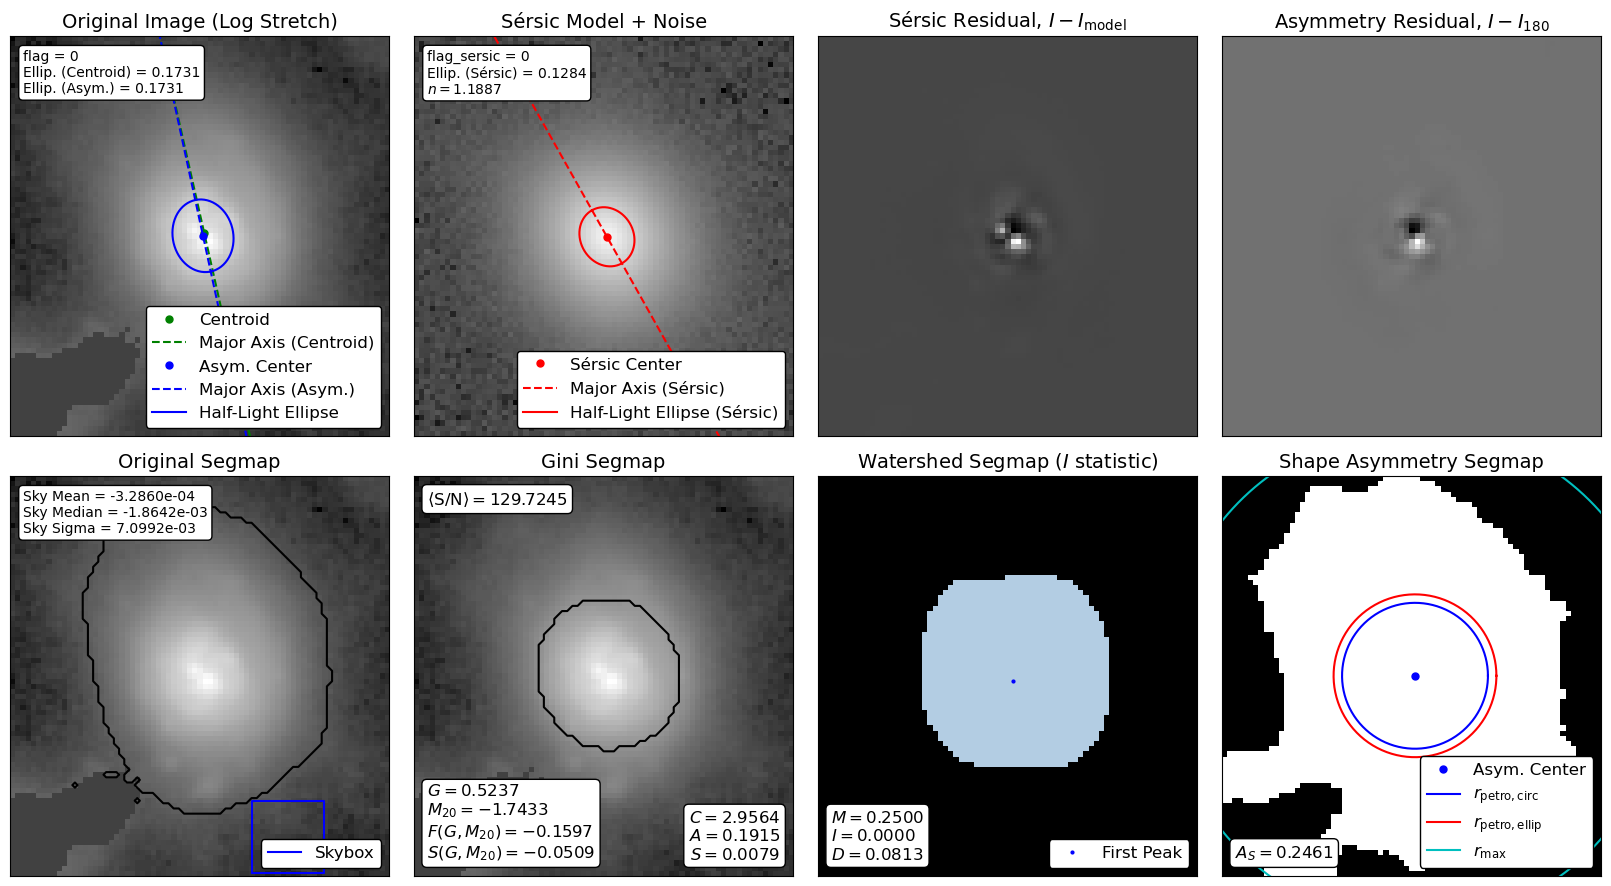

In [121]:
#morph = morphs[0]

fig = make_figure(morph)
plt.show()

In [37]:
##################################### TESTING A DIFFERENT GALAXY #######################################################################

In [38]:
image_211158 = fits.open(path+'cutout_sci_211158.0.fits')[0].data
segmap_211158 = fits.open(path+'segmap_211158.0.fits')[0].data ### generated w/ sep
weightmap_211158 = fits.open(path+'cutout_err_211158.0.fits')[0].data
mask_211158 = fits.open(path+'mask_211158.0.fits')[0].data

mask_bool_211158 = mask_211158.astype(bool)

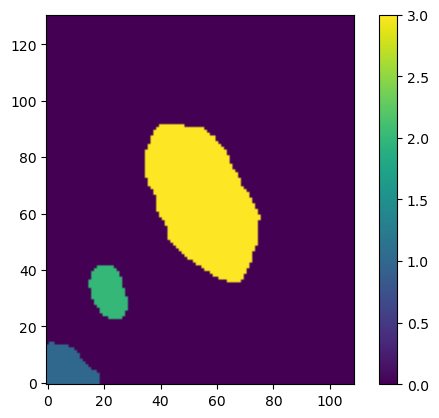

In [39]:
plt.imshow(segmap_211158, origin='lower')
plt.colorbar()
plt.show()

In [40]:
np.unique(segmap_211158)

array([0, 1, 2, 3], dtype='>i4')

In [41]:
morphs_211158 = statmorph.source_morphology( # morphs is a list of SourceMorphology objects (one per label)
    image_211158,
    segmap_211158,
    #segmap_data,            
    weightmap=weightmap_211158,
    mask=mask_bool_211158,
    psf=psf,
#     cutout_extent=10,
#     skybox_size=60,
#     petro_extent_flux=4,
#     verbose=True
)


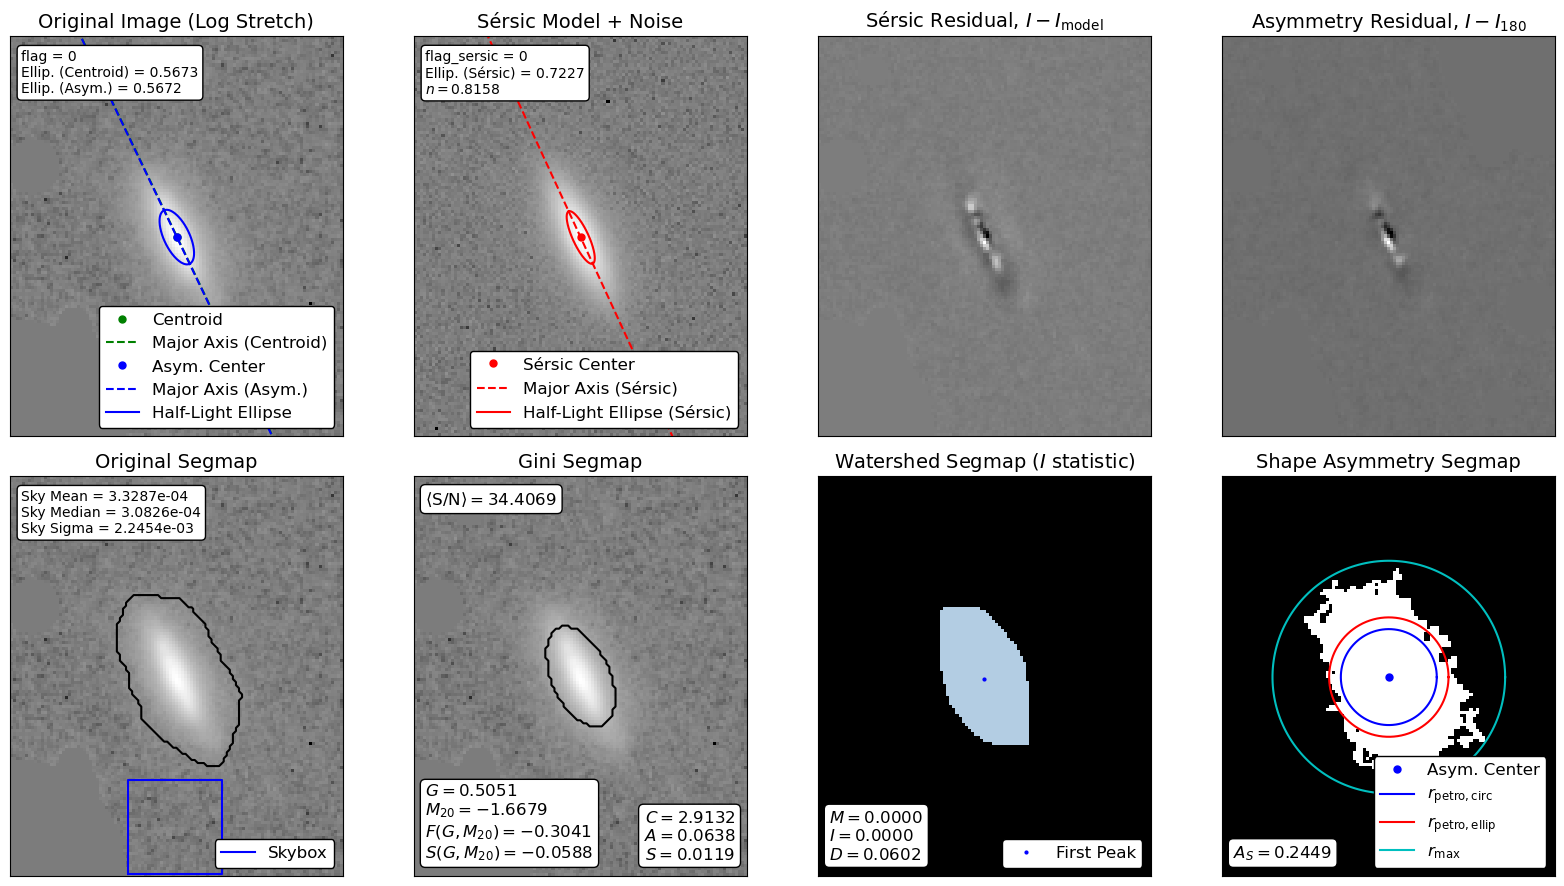

In [42]:
morph_211158 = morphs_211158[2]

fig = make_figure(morph_211158)
plt.show()